<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/2_Coupled_Transmons_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Two-Coupled Transmon Processor

This script configures a two-qubit superconducting processor layout utilizing Quantum Metal (QM). The design integrates two Transmon Pocket (TP) qubits coupled via a Route Meander (RM) quantum bus. The primary Coplanar Waveguide (CPW) feedline incorporates Coupled Line Tee (CLT) elements for readout resonator coupling and Cap N Interdigital Tee (CNIT) components positioned near the Wirebond Launchpads (WL) to mediate external microwave inputs. Ground plane cheesing promotes uniform fabrication, restricted to maintain a 100-micron clearance from the external footprint edges to ensure structural integrity.

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

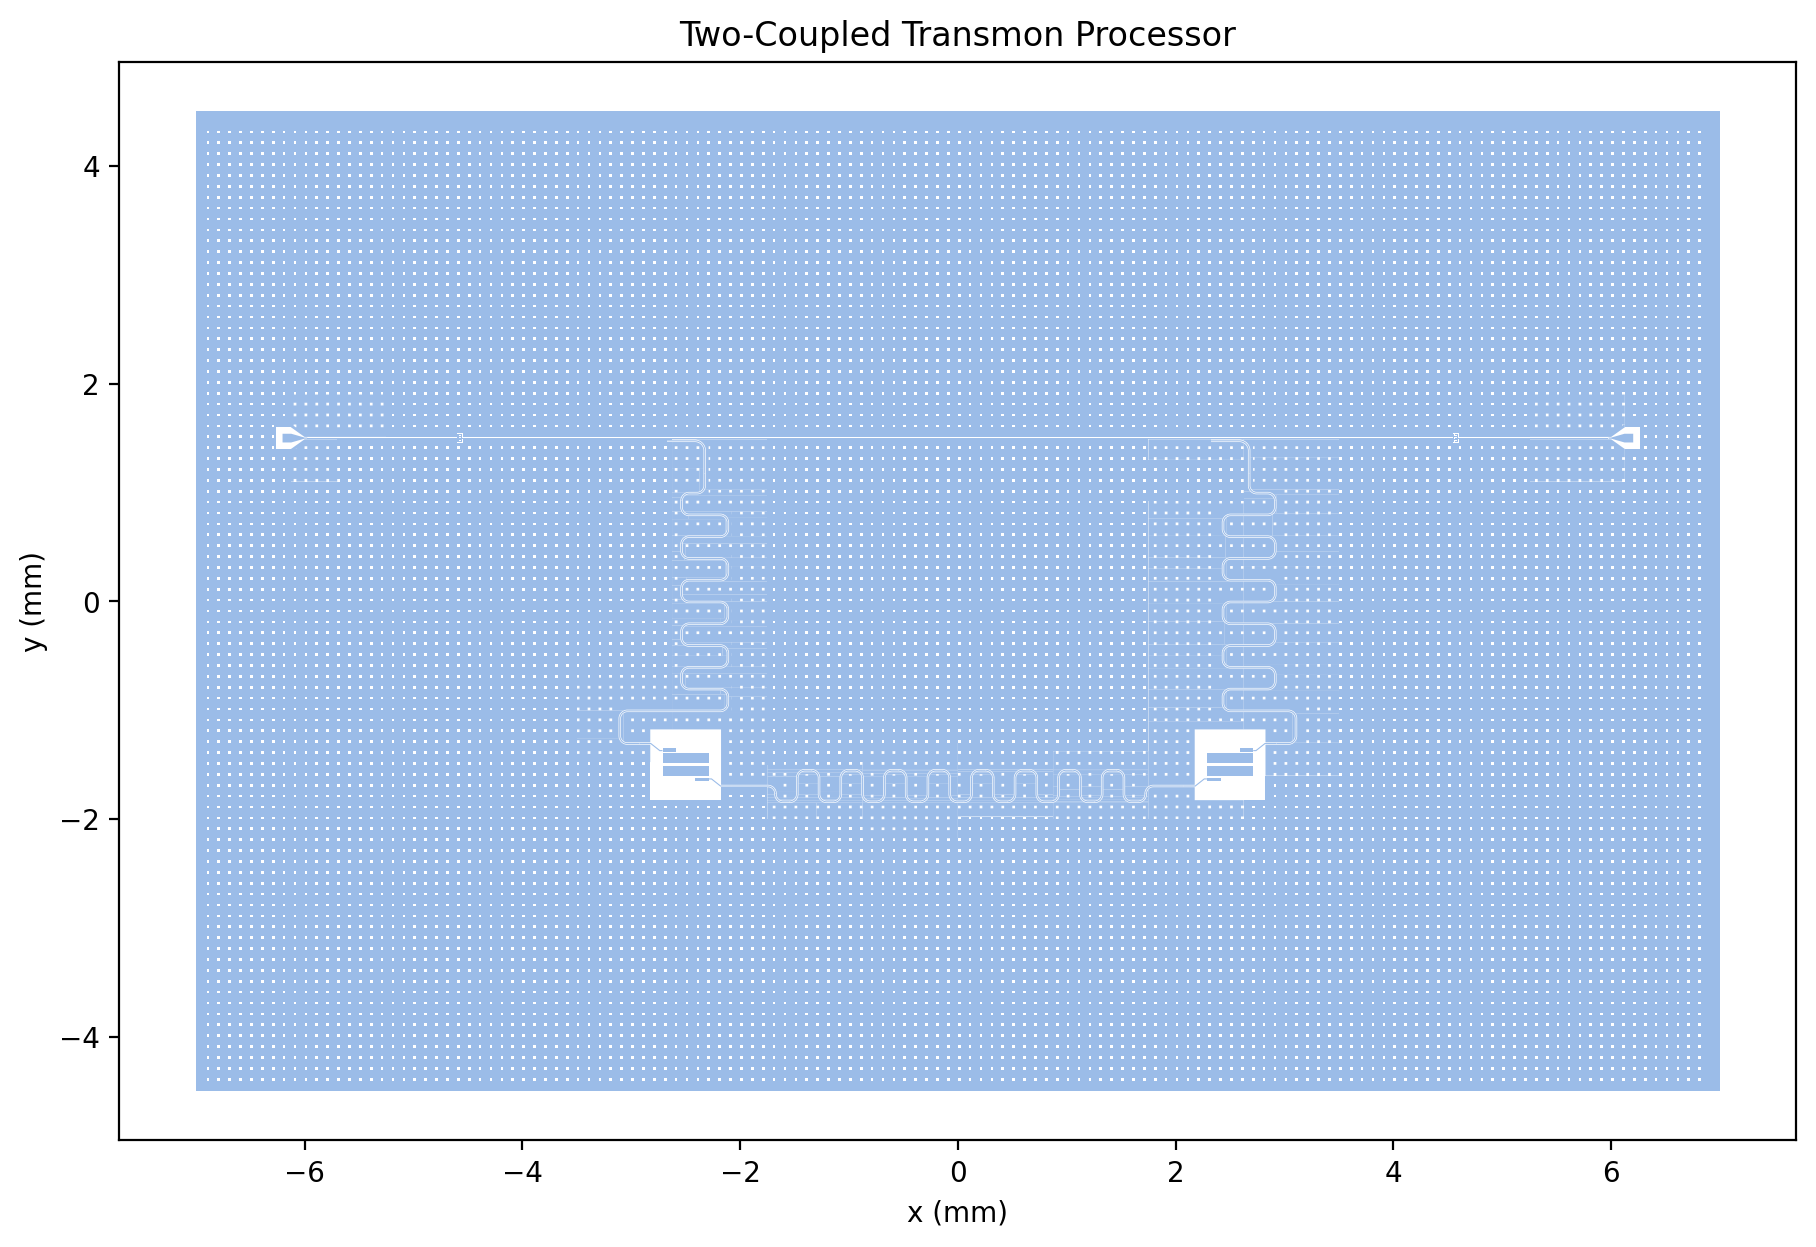

/content/2_Coupled_Transmons_Layout.gds

In [10]:
"""This script synthesizes a Quantum Metal GDSII layout for a two-transmon quantum processor.
"""

# Control Knobs
CHIP_SIZE_X = "14mm"
CHIP_SIZE_Y = "9mm"
OUTPUT_FILENAME = "2_Coupled_Transmons_Layout.gds"

# Imports and Design
import logging
import os
import warnings
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("py.warnings").setLevel(logging.ERROR)

import gdstk
import matplotlib.pyplot as plt
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

plt.rcParams["figure.dpi"] = 200

previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    try:
        design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
        design.chips.main.size.size_x = CHIP_SIZE_X
        design.chips.main.size.size_y = CHIP_SIZE_Y
        design.variables.cpw_width = "10um"
        design.variables.cpw_gap = "6um"
        gds_renderer = QGDSRenderer(design)
        design.renderers.gds = gds_renderer

        # Qubits, Couplers, and Launchpads
        TransmonPocket(
            design,
            "Q1",
            options=dict(
                pos_x="-2.5mm",
                pos_y="-1.5mm",
                pad_width="425um",
                pocket_height="650um",
                connection_pads=dict(
                    readout=dict(loc_W=-1, loc_H=1),
                    coupler=dict(loc_W=1, loc_H=-1),
                ),
            ),
        )
        TransmonPocket(
            design,
            "Q2",
            options=dict(
                pos_x="2.5mm",
                pos_y="-1.5mm",
                pad_width="425um",
                pocket_height="650um",
                connection_pads=dict(
                    readout=dict(loc_W=1, loc_H=1),
                    coupler=dict(loc_W=-1, loc_H=-1),
                ),
            ),
        )

        CoupledLineTee(
            design,
            "clt1",
            options=dict(
                pos_x="-2.5mm",
                pos_y="1.5mm",
                coupling_length="350um",
                down_length="300um",
                fillet="90um",
                open_termination=False,
            ),
        )
        CoupledLineTee(
            design,
            "clt2",
            options=dict(
                pos_x="2.5mm",
                pos_y="1.5mm",
                coupling_length="350um",
                down_length="300um",
                fillet="90um",
                open_termination=False,
            ),
        )
        CapNInterdigital(
            design, "cap1", options=dict(pos_x="-4.5mm", pos_y="1.5mm", orientation="270")
        )
        CapNInterdigital(
            design, "cap2", options=dict(pos_x="4.5mm", pos_y="1.5mm", orientation="90")
        )
        LaunchpadWirebond(
            design,
            "LP1",
            options=dict(pos_x="-6.0mm", pos_y="1.5mm", orientation="0"),
        )
        LaunchpadWirebond(
            design,
            "LP2",
            options=dict(pos_x="6.0mm", pos_y="1.5mm", orientation="180"),
        )

        # Feedline, Readout Resonators, and Bus Routing
        routing_paths = [
            ("feed_LP1_cap1", "LP1", "tie", "cap1", "south_end"),
            ("feed_cap1_clt1", "cap1", "north_end", "clt1", "prime_start"),
            ("feed_clt1_clt2", "clt1", "prime_end", "clt2", "prime_start"),
            ("feed_clt2_cap2", "clt2", "prime_end", "cap2", "north_end"),
            ("feed_cap2_LP2", "cap2", "south_end", "LP2", "tie"),
        ]

        for name, start_comp, start_pin, end_comp, end_pin in routing_paths:
            RoutePathfinder(
                design,
                name,
                options=dict(
                    fillet="90um",
                    pin_inputs=Dict(
                        start_pin=Dict(component=start_comp, pin=start_pin),
                        end_pin=Dict(component=end_comp, pin=end_pin),
                    ),
                ),
            )

        RouteMeander(
            design,
            "read1",
            options=dict(
                fillet="70um",
                total_length="7.0mm",
                lead=Dict(start_straight="180um", end_straight="180um"),
                meander=Dict(spacing="200um", asymmetry="0um"),
                prevent_short_edges="true",
                pin_inputs=Dict(
                    start_pin=Dict(component="clt1", pin="second_end"),
                    end_pin=Dict(component="Q1", pin="readout"),
                ),
            ),
        )
        RouteMeander(
            design,
            "read2",
            options=dict(
                fillet="70um",
                total_length="7.2mm",
                lead=Dict(start_straight="180um", end_straight="180um"),
                meander=Dict(spacing="200um", asymmetry="0um"),
                prevent_short_edges="true",
                pin_inputs=Dict(
                    start_pin=Dict(component="clt2", pin="second_end"),
                    end_pin=Dict(component="Q2", pin="readout"),
                ),
            ),
        )
        RouteMeander(
            design,
            "coupler_bus",
            options=dict(
                fillet="70um",
                total_length="8.0mm",
                lead=Dict(start_straight="200um", end_straight="200um"),
                meander=Dict(spacing="200um", asymmetry="0um"),
                prevent_short_edges="true",
                pin_inputs=Dict(
                    start_pin=Dict(component="Q1", pin="coupler"),
                    end_pin=Dict(component="Q2", pin="coupler"),
                ),
            ),
        )

        # Native Cheesing and GDS Export
        gds_renderer.options.precision = "1e-9"
        gds_renderer.options.tolerance = "1e-6"
        gds_renderer.options.fabricate = "True"
        gds_renderer.options.short_segments_to_not_fillet = "False"
        gds_renderer.options.path_filename = ""

        gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
        gds_renderer.options.cheese.edge_nocheese = "112.5um"
        gds_renderer.options.cheese.view_in_file = Dict(main={1: True})
        gds_renderer.options.no_cheese.view_in_file = Dict(main={1: False})

        junction_table = design.qgeometry.tables["junction"].copy(deep=True)
        design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()

        out_path = Path.cwd() / OUTPUT_FILENAME
        export_status = gds_renderer.export_to_gds(str(out_path))
        design.qgeometry.tables["junction"] = junction_table

        cell_names = {cell.name for cell in gds_renderer.lib.cells}
        for cell in gds_renderer.lib.cells:
            for reference in list(cell.references):
                if reference.cell_name not in cell_names:
                    cell.remove(reference)
        gds_renderer.lib.write_gds(str(out_path))
    finally:
        qm.logger.setLevel(previous_log_level)

# In-Memory GDS Preview
verified_gds = gdstk.read_gds(str(out_path))
top_cells = verified_gds.top_level()
exported_polygons = top_cells[0].get_polygons()

fig, ax = plt.subplots(figsize=(11, 7))
ax.add_collection(
    PolyCollection(
        [polygon.points for polygon in exported_polygons if polygon.layer == 1],
        facecolor="#9bbce8",
        edgecolor="none",
        rasterized=True,
    )
)
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(
    xlabel="x (mm)",
    ylabel="y (mm)",
    title="Two-Coupled Transmon Processor",
)
plt.show()
display(FileLink(str(out_path)))